<a href="https://colab.research.google.com/github/bazb-hub/BB_AAI698O/blob/main/Project_NB_cattle_disease_detection_2stage_model_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Applied AI for Cattle Health Status Detection & Disease Family Classification
## A 2-Stage ML Approach
**Course & Project:** AAI6980 Applied AI Project  
**Student Name:** Bahaa Baz  
**Input Datasets:**
1. Initial Dataset `global_cattle_disease_detection_dataset.csv` (250,000 records, 40 features) from Kaggle: https://www.kaggle.com/datasets/shahhet2812/cattle-health-and-feeding-data
2. `Cattle-Disease_Family_10Groups.csv` (Mapping 44 specific diseases into 10 clinical disease families)

---
### Project Implementation & Considerations
This project implements a **hierarchical 2-stage machine learning framework**:
* **Stage 1 (Binary Health Screening):** Rapidly screens the entire herd to detect whether a cattle record indicates a healthy animal or an abnormal/diseased state. We strictly prioritize **Recall (Sensitivity)** to prevent false negatives (missing a sick animal).
* **Stage 2 (Disease Family Allocation):** For records flagged with disease in Stage 1, the model categorizes the condition into one of **ten clinically coherent disease families**. We evaluate this stage using **Macro-F1** to ensure that rare, high-consequence conditions receive equal evaluation weight.
* **Clinical Framing:** This system is explicitly designed as a **Decision Support Tool (DST)** to assist veterinarians and herd management in prioritizing animals for physical examination, preserving the human-in-the-loop clinical standard.
* **Dataset Used:** The dataset used for developing and testing the model is Completely based on _Synthetic Data_ and does not use Real data.


In [17]:
# Step 0: Import the required libraries
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing & metrics
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve
)
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Imbalance handling & Gradient Boosting
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier, DMatrix

# Plotting configurations
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("All libraries imported successfully!")


All libraries imported successfully!


---
## Task 1: Dataset Ingestion & Target Derivation
Loading the input files:
1. `global_cattle_disease_detection_dataset.csv`: Contains 250,000 tabular cattle records with animal biometrics, behavioral sensors, feeding records, environment variables, vaccination history, and milk productivity.
2. `Cattle-Disease_Family_10Groups.csv`: The clinical taxonomy categorizing the 44 specific bovine diseases into 10 broad physiological groups (e.g., *Respiratory*, *Metabolic*, *Gastrointestinal*, *Udder and mammary*).

Then deriving the two modeling targets:
- **`Disease_Present` (Stage 1 Target):** Binary indicator (`0 = Healthy`, `1 = Diseased`).
- **`Disease_Family` (Stage 2 Target):** Mapped disease group for triage.


In [18]:
# Load the two primary input files
data_file = '/content/global_cattle_disease_detection_dataset-Modified.csv'
diseaseGroup_file = '/content/Cattle-Disease_Family_10Groups.csv'

df = pd.read_csv(data_file)
groups_df = pd.read_csv(diseaseGroup_file)

print(f"Loaded Primary Dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Loaded Disease Taxonomy: {groups_df.shape[0]} diseases mapped to {groups_df['Disease Family / Group'].nunique()} families")

# Derive Stage 1 Target: Binary Health Status (0 = Healthy, 1 = Disease Present)
df['Disease_Present'] = (df['Disease_Status'] != 'Healthy').astype(int)

# Derive Stage 2 Target: Disease Family mapping from the 44 diseases
disease_to_family = dict(zip(groups_df['Disease'], groups_df['Disease Family / Group']))
df['Disease_Family'] = df['Disease_Status'].map(disease_to_family).fillna('No Disease')

print(f"\nStage 1 Target Distribution (Disease_Present):")
print(df['Disease_Present'].value_counts(normalize=True).round(3))
print(f"\nStage 2 Target Distribution (Top 5 Disease Families):")
print(df[df['Disease_Present'] == 1]['Disease_Family'].value_counts().head(5))


Loaded Primary Dataset: 250,000 rows, 40 columns
Loaded Disease Taxonomy: 44 diseases mapped to 10 families

Stage 1 Target Distribution (Disease_Present):
Disease_Present
0    0.55
1    0.45
Name: proportion, dtype: float64

Stage 2 Target Distribution (Top 5 Disease Families):
Disease_Family
Metabolic and nutritional          20469
Gastrointestinal and enteric       17911
Systemic infectious disease        12793
Reproductive and periparturient    12793
Vector-borne and hemoparasitic     10236
Name: count, dtype: int64


In [19]:
# Verifying the Dataframe structure
df.head()

,Cattle_ID,Breed,Region,Country,Climate_Zone,Management_System,Age_Months,Weight_kg,Parity,Lactation_Stage,...,BVD_Vaccine,Rabies_Vaccine,Previous_Week_Avg_Yield,Body_Condition_Score,Milking_Interval_hrs,Date,Farm_ID,Disease_Status,Disease_Present,Disease_Family
0,CATTLE_000001,Rathi,South_America,ET,Subtropical,Mixed,56,363.9,3,Mid,...,0,0,24.84,3.7,12,2026-02-16,FARM_062,Healthy,0,No Disease
1,CATTLE_000002,Gangatiri,Europe_NA,KE,Temperate,Mixed,130,604.8,1,Mid,...,1,0,10.71,3.3,10,2026-03-10,FARM_054,Healthy,0,No Disease
2,CATTLE_000003,Australian_Milking_Zebu,South_America,BR,Temperate,Extensive,93,345.3,1,Late,...,1,0,22.70,3.3,10,2026-04-03,FARM_028,Healthy,0,No Disease
3,CATTLE_000004,Hariana,Oceania,FR,Temperate,Mixed,46,568.3,3,Early,...,0,0,19.88,2.9,14,2026-07-04,FARM_009,Healthy,0,No Disease
4,CATTLE_000005,Rathi,Global,BR,Continental,Semi_Intensive,103,708.9,5,Early,...,1,0,12.84,2.3,10,2026-02-03,FARM_014,Dystocia,1,Reproductive and periparturient


In [20]:
# Showing the details about the Data Schema
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 42 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Cattle_ID                250000 non-null  object 
 1   Breed                    250000 non-null  object 
 2   Region                   250000 non-null  object 
 3   Country                  250000 non-null  object 
 4   Climate_Zone             250000 non-null  object 
 5   Management_System        250000 non-null  object 
 6   Age_Months               250000 non-null  int64  
 7   Weight_kg                250000 non-null  float64
 8   Parity                   250000 non-null  int64  
 9   Lactation_Stage          250000 non-null  object 
 10  Days_in_Milk             250000 non-null  int64  
 11  Feed_Type                250000 non-null  object 
 12  Feed_Quantity_kg         250000 non-null  float64
 13  Water_Intake_L           250000 non-null  float64
 14  Walk

In [21]:
# Diseases Families
#df['Disease_Family'].value_counts()
df[df['Disease_Present'] == 1]['Disease_Present'].value_counts()

,count
Disease_Present,
1,112581


---
## Task 2: Exploratory Data Analysis (EDA) & Domain Insights
Running EDA to explore the underlying data distributions, understand physiological differences between healthy and sick cattle, and check for statistical issues such as multicollinearity.

### 2.1 Target Class Distributions
We first inspect the prevalence in Stage 1 and Stage 2. Notice that ~55% of cattle are healthy and ~45% have a disease. In Stage 2, disease family prevalence varies from common metabolic/enteric disorders down to rarer vector-borne and environmental conditions.


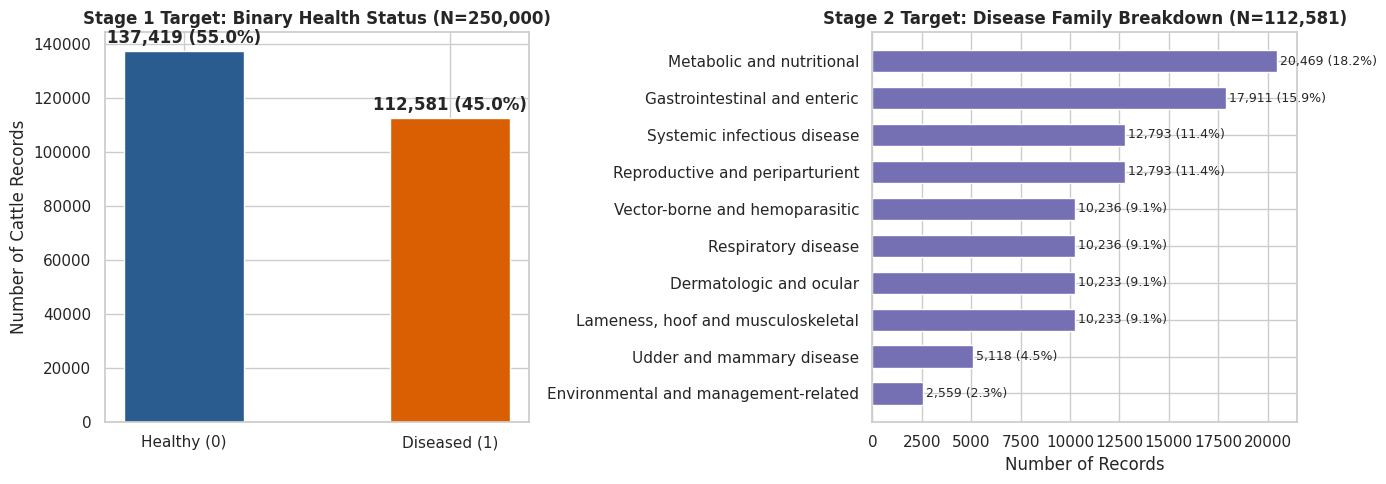

In [22]:
# Plot 2.1: Target Class Distributions for Stage 1 and Stage 2
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Stage 1 Screening Distribution
s1_counts = df['Disease_Present'].value_counts()
labels_s1 = ['Healthy (0)', 'Diseased (1)']
axes[0].bar(labels_s1, s1_counts.values, color=['#2b5c8f', '#d95f02'], width=0.45)
axes[0].set_title('Stage 1 Target: Binary Health Status (N=250,000)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Number of Cattle Records')
for i, v in enumerate(s1_counts.values):
    axes[0].text(i, v + 3000, f"{v:,} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Stage 2 Disease Family Distribution
s2_counts = df[df['Disease_Present'] == 1]['Disease_Family'].value_counts()
total_diseaseCount = df['Disease_Present'].sum()
axes[1].barh(s2_counts.index, s2_counts.values, color='#7570b3', height=0.6)
axes[1].set_title('Stage 2 Target: Disease Family Breakdown (N=112,581)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Records')
axes[1].invert_yaxis()
for i, v in enumerate(s2_counts.values):
    axes[1].text(v + 150, i, f"{v:,} ({v/total_diseaseCount*100:.1f}%)", va='center', fontsize=9)

plt.tight_layout()
plt.show()

### 2.2 Reviewing the Biomarkers & Clinical Signs
In veterinary medicine, core vitals provide the earliest physical signs of disease:
* **Body Temperature:** Healthy cows maintain a temp in the range of 38°C and 38.9°C; illness causes elevation above 39°C.
* **Heart Rate:** The normal range is 52 – 72 bpm. Elevated bpm signals pain or distress.
* **Respiration Rate:** The normal range is 14 – 26 breaths/min.
* **Rumination Time:** Normal active rumination is 8–10 hours/day. A sharp drop can be attributed to disease
* **Milk Yield:** The Average Milk Yield per day is in the range of 12 – 25 Liters. A drop in production is an indicator of health concerns.

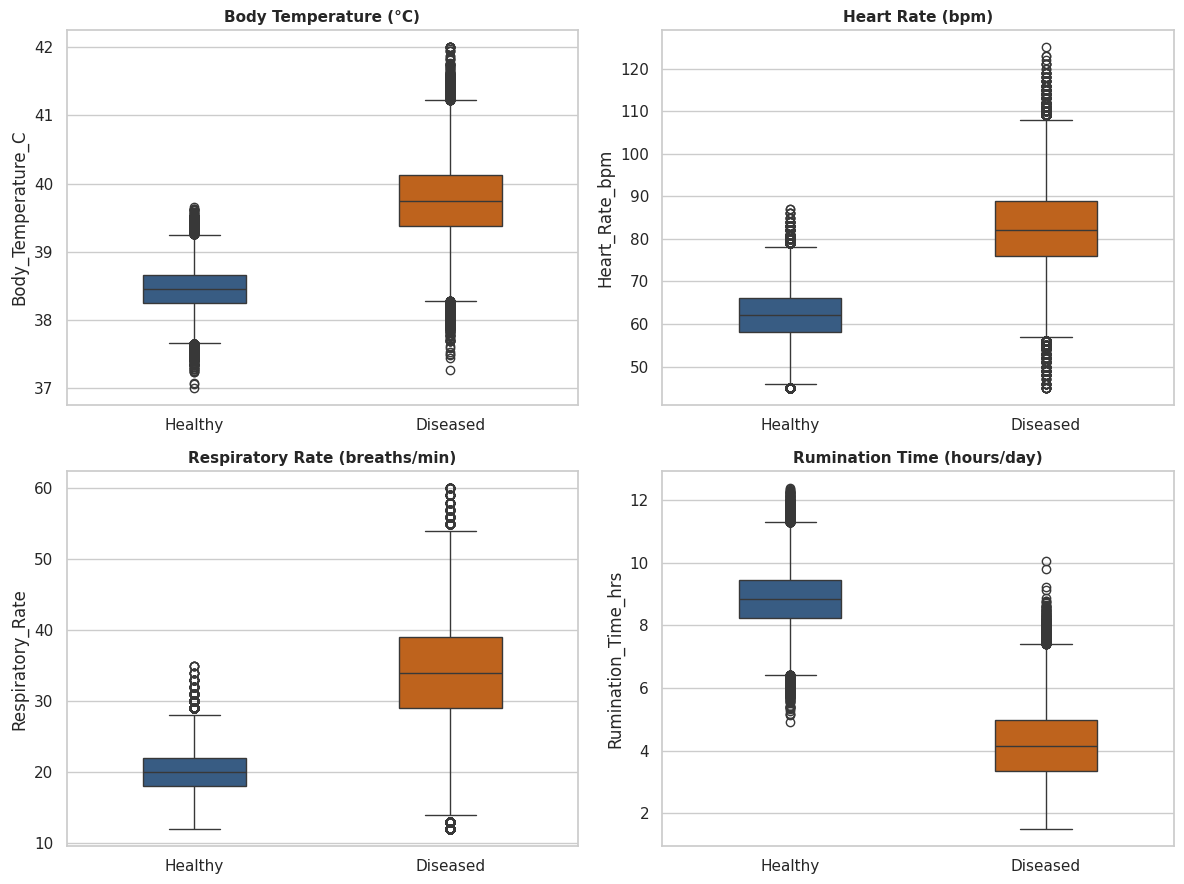

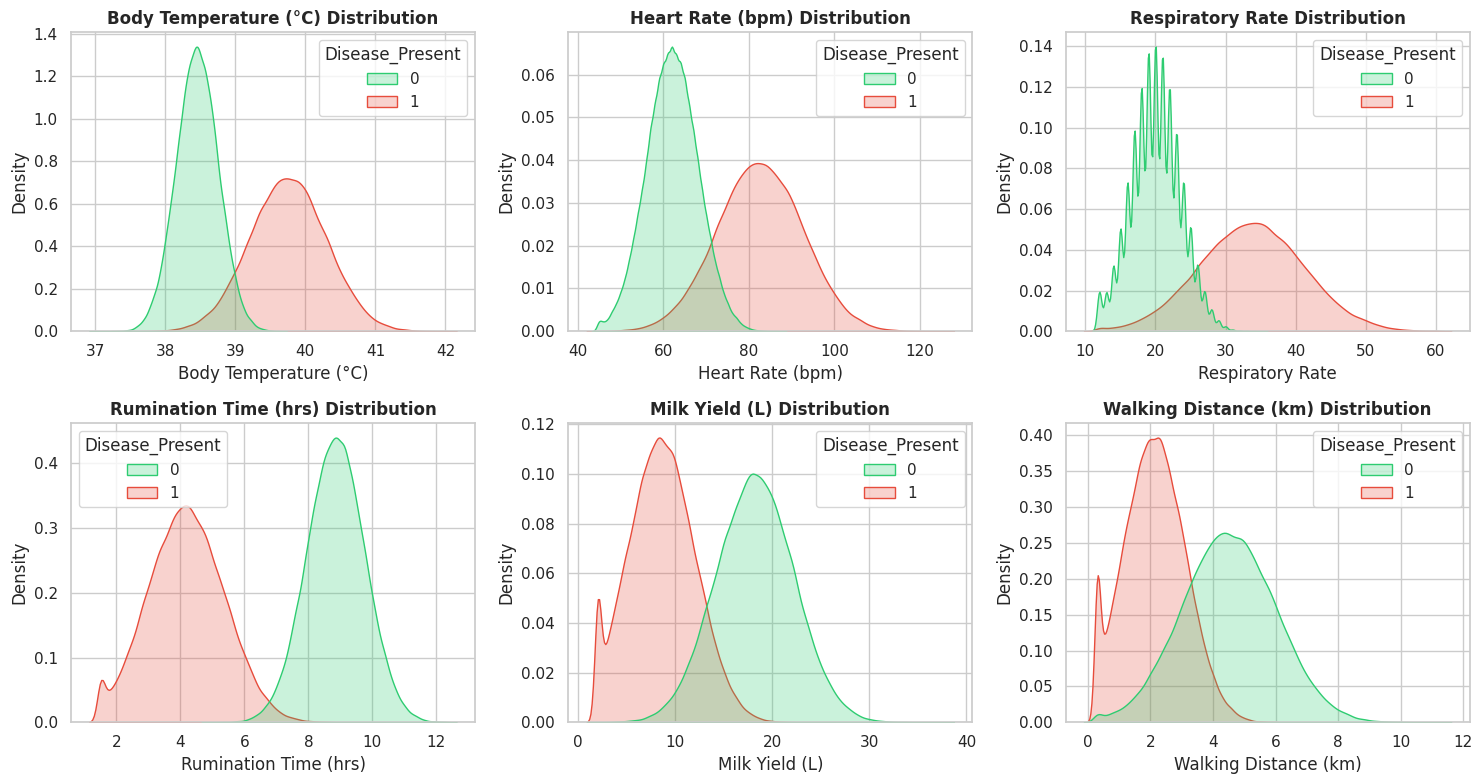

In [23]:
# Plot 2.2: Distribution of Core Biomarkers
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

eda_df = df.copy()
eda_df['Health_Label'] = eda_df['Disease_Present'].map({0: 'Healthy', 1: 'Diseased'})
palette = {'Healthy': '#2b5c8f', 'Diseased': '#d95f02'}

vital_features = [
    ('Body_Temperature_C', 'Body Temperature (°C)', axes[0, 0]),
    ('Heart_Rate_bpm', 'Heart Rate (bpm)', axes[0, 1]),
    ('Respiratory_Rate', 'Respiratory Rate (breaths/min)', axes[1, 0]),
    ('Rumination_Time_hrs', 'Rumination Time (hours/day)', axes[1, 1])
]
# BOX plots
for col, title, ax in vital_features:
    sns.boxplot(data=eda_df, x='Health_Label', y=col, ax=ax, hue='Health_Label', palette=palette, width=0.4, legend=False)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel('')

plt.tight_layout()
plt.show()


# Kernel Density Estimate plots
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
biometrics = ['Body_Temperature_C', 'Heart_Rate_bpm', 'Respiratory_Rate', 'Rumination_Time_hrs', 'Milk_Yield_L', 'Walking_Distance_km']
titles = ['Body Temperature (°C)', 'Heart Rate (bpm)', 'Respiratory Rate', 'Rumination Time (hrs)', 'Milk Yield (L)', 'Walking Distance (km)']

for i, (col, title) in enumerate(zip(biometrics, titles)):
    ax = axes[i//3, i%3]
    sns.kdeplot(data=eda_df, x=col, hue='Disease_Present', common_norm=False, fill=True,
                palette={0: '#2ecc71', 1: '#e74c3c'}, ax=ax)
    ax.set_title(f'{title} Distribution', fontweight='bold')
    ax.set_xlabel(title)
    ax.set_ylabel('Density')

plt.tight_layout()
plt.show()

### 2.3 Multicollinearity Check: Pearson Correlation & Variance Inflation Factor (VIF)
To prevent unstable regression coefficients and verify feature independence, we examine multicollinearity:
* We compute the **Pearson Correlation Matrix** across key continuous predictors.
* We compute the **Variance Inflation Factor (VIF)**:
  * A VIF > 5 indicates moderate collinearity; VIF > 10 indicates severe redundancy.
* **Key Finding:** All physiological vitals (`Body_Temperature_C`, `Heart_Rate_bpm`, `Rumination_Time_hrs`) maintain low VIF values below 3, showing statistical independence.


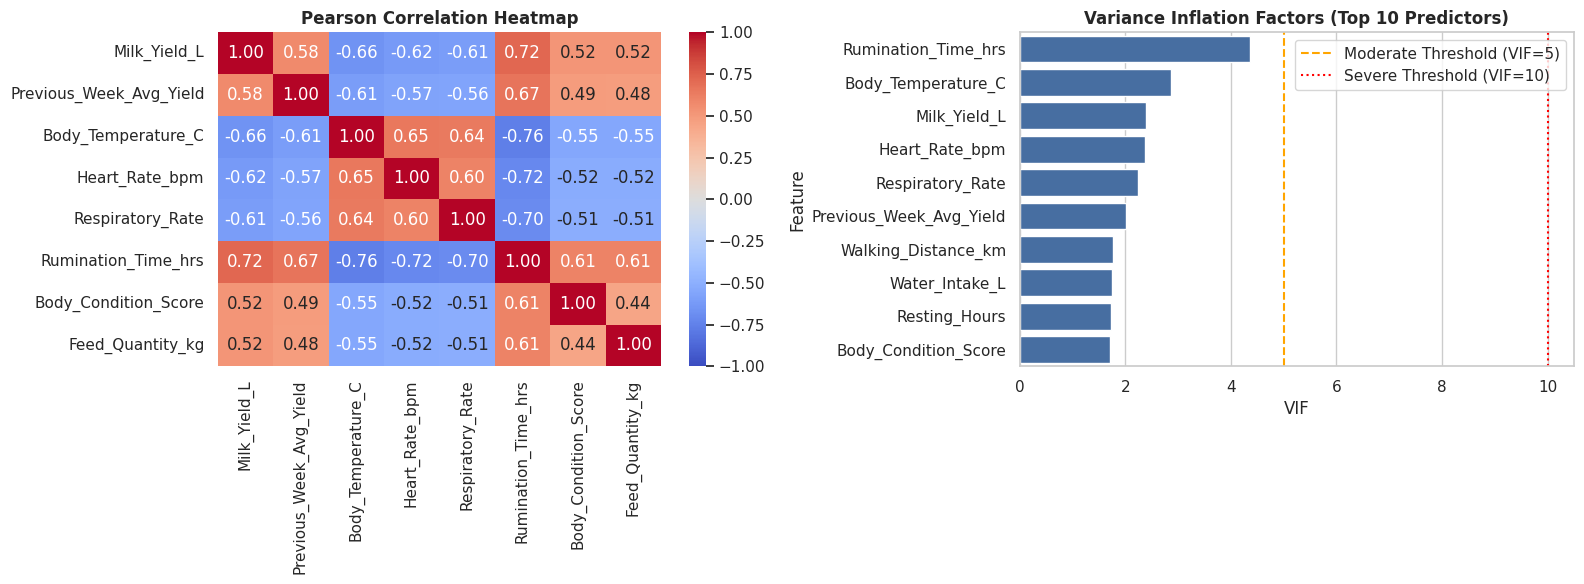

Top 5 VIF Scores:
            Feature      VIF
Rumination_Time_hrs 4.371122
 Body_Temperature_C 2.864281
       Milk_Yield_L 2.402299
     Heart_Rate_bpm 2.376340
   Respiratory_Rate 2.250527


In [25]:
# Plot 2.3: Multicollinearity Audit - Pearson Correlation & VIF Analysis
from statsmodels.stats.outliers_influence import variance_inflation_factor

num_cols_eda = [
    'Age_Months', 'Weight_kg', 'Days_in_Milk', 'Feed_Quantity_kg',
    'Water_Intake_L', 'Walking_Distance_km', 'Rumination_Time_hrs',
    'Resting_Hours', 'Body_Temperature_C', 'Heart_Rate_bpm',
    'Respiratory_Rate', 'Milk_Yield_L', 'Previous_Week_Avg_Yield',
    'Body_Condition_Score'
]

num_df = df[num_cols_eda]
scaler_vif = StandardScaler()
vif_scaled = scaler_vif.fit_transform(num_df)

vif_df = pd.DataFrame({
    'Feature': num_cols_eda,
    'VIF': [variance_inflation_factor(vif_scaled, i) for i in range(len(num_cols_eda))]
}).sort_values('VIF', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Correlation Heatmap for key features
selected_corr = num_df[['Milk_Yield_L', 'Previous_Week_Avg_Yield', 'Body_Temperature_C',
                           'Heart_Rate_bpm', 'Respiratory_Rate', 'Rumination_Time_hrs',
                           'Body_Condition_Score', 'Feed_Quantity_kg']].corr()
sns.heatmap(selected_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson Correlation Heatmap', fontsize=12, fontweight='bold')

# VIF Barplot
sns.barplot(data=vif_df.head(10), x='VIF', y='Feature', ax=axes[1], color='#386cb0')
axes[1].axvline(5.0, color='orange', linestyle='--', label='Moderate Threshold (VIF=5)')
axes[1].axvline(10.0, color='red', linestyle=':', label='Severe Threshold (VIF=10)')
axes[1].set_title('Variance Inflation Factors (Top 10 Predictors)', fontsize=12, fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

print("Top 5 VIF Scores:")
print(vif_df.head(5).to_string(index=False))

---
## Task 3: Dataset Preparation & Preprocessing Pipeline
To prepare the dataset for the model and while preventing data leakage, we follow these steps:
1. **Identifier & Leaky Column Removal:** Drop `Cattle_ID` (unique identifier), `Date` and `Farm_ID` (to avoid memorizing specific farms), and `Disease_Status` (which would leak the granular ground truth).
2. **One-Hot Encoding:** Convert categorical attributes (`Breed`, `Region`, `Country`, `Climate_Zone`, `Management_System`, `Lactation_Stage`, `Feed_Type`, `Season`) into binary dummy columns.
3. **StandardScaler Normalization:** Scale continuous numerical variables to mean 0 and variance 1, which is critical for Regularized Logistic Regression.
4. **Data Partitioning (70% Train, 15% Validation, 15% Test):** We use **stratified sampling** to maintain target class ratios. The 15% test set (37,500 records) is set aside and kept completely untouched until final evaluation.
5. **Class Imbalance Rebalancing (SMOTE):** Synthetic Minority Over-sampling Technique (SMOTE) is applied **strictly on the training partition** to balance the classes without contaminating the validation or test splits.


In [ ]:
# Task 3.1: Clean Non-Predictive Features
drop_cols = ['Cattle_ID', 'Date', 'Farm_ID', 'Disease_Status']
df_clean = df.drop(columns=drop_cols)

# Define column categories
# Numerical Columns
num_cols = [
    'Age_Months', 'Weight_kg', 'Parity', 'Days_in_Milk', 'Feed_Quantity_kg',
    'Water_Intake_L', 'Walking_Distance_km', 'Grazing_Duration_hrs',
    'Rumination_Time_hrs', 'Resting_Hours', 'Body_Temperature_C',
    'Heart_Rate_bpm', 'Respiratory_Rate', 'Ambient_Temperature_C',
    'Humidity_percent', 'Housing_Score', 'Milk_Yield_L',
    'Previous_Week_Avg_Yield', 'Body_Condition_Score', 'Milking_Interval_hrs'
]
# Categorical Columns
cat_cols = ['Breed', 'Region', 'Country', 'Climate_Zone', 'Management_System', 'Lactation_Stage', 'Feed_Type', 'Season']
vaccine_cols = ['FMD_Vaccine', 'Brucellosis_Vaccine', 'HS_Vaccine', 'BQ_Vaccine',
                'Anthrax_Vaccine', 'IBR_Vaccine', 'BVD_Vaccine', 'Rabies_Vaccine']

# Check missing values and duplicates
print(f"Dataset Quality Check -> Duplicates: {df_clean.duplicated().sum()}, Missing Values: {df_clean.isnull().sum().sum()}")

# Task 3.2 & 3.3: One-Hot Encoding & StandardScaler
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
scaler = StandardScaler()

X_num = scaler.fit_transform(df_clean[num_cols])
X_cat = ohe.fit_transform(df_clean[cat_cols])
X_vac = df_clean[vaccine_cols].values

cat_feature_names = ohe.get_feature_names_out(cat_cols).tolist()
all_feature_names = num_cols + cat_feature_names + vaccine_cols

X_all = np.hstack([X_num, X_cat, X_vac]).astype(np.float32)
y_stage1 = df_clean['Disease_Present'].values

print(f"Total Processed Features: {X_all.shape[1]} (20 numerical, {len(cat_feature_names)} one-hot, 8 vaccine flags)")

# Task 3.4: Data Partitioning (70% Train, 15% Validation, 15% Test)
X_train_val_s1, X_test_s1, y_train_val_s1, y_test_s1 = train_test_split(
    X_all, y_stage1, test_size=0.15, random_state=42, stratify=y_stage1
)
X_train_s1, X_val_s1, y_train_s1, y_val_s1 = train_test_split(
    X_train_val_s1, y_train_val_s1, test_size=0.17647, random_state=42, stratify=y_train_val_s1
)

print(f"Stage 1 Partitioning -> Train: {X_train_s1.shape[0]:,}, Validation: {X_val_s1.shape[0]:,}, Test: {X_test_s1.shape[0]:,}")

# Task 3.5: Apply SMOTE on Training Set Only
smote_s1 = SMOTE(random_state=42)
X_train_s1_res, y_train_s1_res = smote_s1.fit_resample(X_train_s1, y_train_s1)
print(f"SMOTE Rebalancing -> Balanced Training Samples: {X_train_s1_res.shape[0]:,}")


---
## Task 4: Stage 1 Model Execution & Validation (Binary Health Screening)
Here we will train and compare three distinct machine learning algorithms:
1. **Regularized Logistic Regression (L2):** An interpretable linear baseline that provides well-calibrated probabilities.
2. **Random Forest:** An ensemble of bagged decision trees capable of capturing non-linear feature interactions without overfitting.
3. **XGBoost (Extreme Gradient Boosting):** An optimized gradient boosted decision tree framework.

### Evaluation Metrics for Stage 1:
As per the project proposal, here are the evaluation metrics for the first stage:
* **Recall (Sensitivity):** $\frac{TP}{TP + FN}$ — **Primary Metric.** A false negative represents a diseased cow misclassified as healthy, risking herd contagion and untreated animal suffering.
* **Precision:** $\frac{TP}{TP + FP}$ — Measures alert reliability.
* **Specificity:** $\frac{TN}{TN + FP}$ — Quantifies correct identification of healthy animals to avoid alert fatigue.
* **F1-Score:** Harmonic mean of precision and recall.
* **ROC-AUC & PR-AUC:** Discrimination ability across all classification thresholds.
* **Confusion Matrix:** Shows raw counts of TP, FP, TN, and FN on the unseen test set.


In [ ]:
# Step 4.1: Training Stage 1 Models and Evaluating them on Held-Out Test Set (37,500 records)
models_s1 = {
    'Regularized Logistic Regression': LogisticRegression(C=1.0, max_iter=200, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=40, max_depth=12, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=60, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42, eval_metric='logloss')
}

results_s1 = {}
for name, model in models_s1.items():
    model.fit(X_train_s1_res, y_train_s1_res)
    y_pred = model.predict(X_test_s1)
    y_prob = model.predict_proba(X_test_s1)[:, 1]

    cm = confusion_matrix(y_test_s1, y_pred)
    tn, fp, fn, tp = cm.ravel()

    results_s1[name] = {
        'Precision': precision_score(y_test_s1, y_pred),
        'Recall (Sensitivity)': recall_score(y_test_s1, y_pred),
        'Specificity': tn / (tn + fp),
        'F1-Score': f1_score(y_test_s1, y_pred),
        'ROC-AUC': roc_auc_score(y_test_s1, y_prob),
        'PR-AUC': average_precision_score(y_test_s1, y_prob),
        'CM': cm,
        'y_prob': y_prob,
        'model': model
    }

# Display Stage 1 Comparison Table
df_res_s1 = pd.DataFrame(results_s1).T[['Recall (Sensitivity)', 'Precision', 'Specificity', 'F1-Score', 'ROC-AUC', 'PR-AUC']]
print("=== STAGE 1 HELD-OUT TEST EVALUATION (N=37,500) ===")
print(df_res_s1.round(4))


In [ ]:
# Plot 4.2: Stage 1 ROC Curves, Precision-Recall Curves, and Confusion Matrix
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ROC Curves
for name, r in results_s1.items():
    fpr, tpr, _ = roc_curve(y_test_s1, r['y_prob'])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={r['ROC-AUC']:.3f})", lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_title('Stage 1 ROC Curves (Held-Out Test Set)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

# Precision-Recall Curves
for name, r in results_s1.items():
    prec, rec, _ = precision_recall_curve(y_test_s1, r['y_prob'])
    axes[1].plot(rec, prec, label=f"{name} (PR-AUC={r['PR-AUC']:.3f})", lw=2)
axes[1].set_title('Stage 1 Precision-Recall Curves', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Recall (Sensitivity)')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

# Confusion Matrix (RLR)
best_cm = results_s1['Regularized Logistic Regression']['CM']
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
            xticklabels=['Pred Healthy', 'Pred Diseased'], yticklabels=['Actual Healthy', 'Actual Diseased'])
axes[2].set_title('Stage 1 RLR Confusion Matrix (Test Set)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


---
## Task 5: Stage 2 Model Execution & Validation (Disease Family Classification)
In Stage 2, we will evaluate the models on **disease-present records only** (`Disease_Present == 1`, N=112,581). The goal is to classify each sick animal into one of the 10 clinical disease families.

### Evaluation Metrics for Stage 2:
* **Macro-F1:** **Primary Metric.** Computes the unweighted arithmetic mean of F1-scores across all 10 families, ensuring rare conditions (e.g., *Environmental* or *Udder and mammary*) contribute equally alongside common conditions.
* **Weighted-F1:** Summarizes performance weighted by class support.
* **Per-Class Recall and Precision:** Identifies specific families that are well-separated versus those that experience confusion.
* **Normalized Confusion Matrix:** Displays true positive and error rates across all 10 disease families.


In [ ]:
import math
# Step 5.1: Stage 2 Data Preparation & Partitioning
disease_mask = (df_clean['Disease_Present'] == 1)
X_s2_all = X_all[disease_mask]
y_s2_all = df_clean.loc[disease_mask, 'Disease_Family'].values

families_s2 = sorted(np.unique(y_s2_all))
fam_to_id = {fam: i for i, fam in enumerate(families_s2)}
id_to_fam = {i: fam for i, fam in enumerate(families_s2)}
y_s2_enc = np.array([fam_to_id[f] for f in y_s2_all])

print(f"Stage 2 Cohort: {X_s2_all.shape[0]:,} diseased cattle records across {len(families_s2)} families")
heldout_records = math.ceil(X_s2_all.shape[0] * 0.15)
print(f"Held-Out Test Set: {heldout_records:,} records")

# Split Stage 2 into 70% Train, 15% Validation, 15% Test
X_train_val_s2, X_test_s2, y_train_val_s2, y_test_s2 = train_test_split(
    X_s2_all, y_s2_enc, test_size=0.15, random_state=42, stratify=y_s2_enc
)
X_train_s2, X_val_s2, y_train_s2, y_val_s2 = train_test_split(
    X_train_val_s2, y_train_val_s2, test_size=0.15, random_state=42, stratify=y_train_val_s2
)

# Apply SMOTE to balance minority disease families in training
smote_s2 = SMOTE(random_state=42)
X_train_s2_res, y_train_s2_res = smote_s2.fit_resample(X_train_s2, y_train_s2)
print(f"Stage 2 Training set resampled with SMOTE to: {X_train_s2_res.shape[0]:,} samples")

# Step 5.2: Train and Compare Stage 2 Multi-Class Models
models_s2 = {
    'Regularized Logistic Regression': LogisticRegression(C=1.0, max_iter=200, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=50, max_depth=12, n_jobs=-1, random_state=42),
    'XGBoost': XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, n_jobs=-1, random_state=42, eval_metric='mlogloss')
}

results_s2 = {}
for name, model in models_s2.items():
    model.fit(X_train_s2_res, y_train_s2_res)
    y_pred = model.predict(X_test_s2)
    results_s2[name] = {
        'Macro-F1 (Primary)': f1_score(y_test_s2, y_pred, average='macro'),
        'Weighted-F1': f1_score(y_test_s2, y_pred, average='weighted'),
        'y_pred': y_pred,
        'model': model
    }

df_res_s2 = pd.DataFrame(results_s2).T[['Macro-F1 (Primary)', 'Weighted-F1']]
print("\n=== STAGE 2 HELD-OUT TEST EVALUATION (10 FAMILIES, N=16,888) ===")
print(df_res_s2.round(4))


In [ ]:
# Plot 5.3: Normalized Confusion Matrix for Stage 2 Multi-Class Triage
fig, ax = plt.subplots(figsize=(10, 8))
cm_s2 = confusion_matrix(y_test_s2, results_s2['Regularized Logistic Regression']['y_pred'], normalize='true')
sns.heatmap(cm_s2, annot=True, fmt='.2f', cmap='YlGnBu', ax=ax,
            xticklabels=families_s2, yticklabels=families_s2)
ax.set_title('Stage 2 RLR Normalized Confusion Matrix (Test Set)', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Disease Family')
ax.set_ylabel('True Disease Family')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Display Per-Class Precision, Recall, and F1-Score for XGBoost
print("=== STAGE 2 RLR PER-CLASS CLASSIFICATION REPORT ===")
print(classification_report(y_test_s2, results_s2['Regularized Logistic Regression']['y_pred'], target_names=families_s2, digits=3))


---
## Task 6: Model Explainability with SHAP (Shapley Additive Explanations)
A critical requirement of our applied AI proposal is ensuring **model interpretability**. Because the model interpretation is a challenge, veterinarians cannot adopt them unless they understand *why* an animal was flagged.

We use **Tree SHAP** to compute Shapley values for the Stage 1 XGBoost model. SHAP fairly distributes the credit of the prediction among all input features.
* Features with the highest mean absolute SHAP value $|\text{SHAP}|$ exert the greatest influence on shifting the model's prediction from healthy to diseased.


In [ ]:
# Step 6.1: Compute Native Tree SHAP Attributions for Stage 1 XGBoost Model
sample_test_idx = np.random.choice(len(X_test_s1), 1000, replace=False)
X_test_sample = X_test_s1[sample_test_idx]
dtest_sample = DMatrix(X_test_sample)

xgb_s1_model = results_s1['XGBoost']['model']
shap_contribs = xgb_s1_model.get_booster().predict(dtest_sample, pred_contribs=True)
shap_values = shap_contribs[:, :-1] # Exclude base margin bias term
mean_abs_shap = np.mean(np.abs(shap_values), axis=0)

shap_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Mean_SHAP': mean_abs_shap
}).sort_values('Mean_SHAP', ascending=False)

# Plot Top 10 Feature Importances
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=shap_df.head(10), x='Mean_SHAP', y='Feature', ax=ax, color='#2c7bb6')
ax.set_title('Top 10 Feature Importances (Tree SHAP - Stage 1 XGBoost)', fontsize=12, fontweight='bold')
ax.set_xlabel('Mean Absolute SHAP Value |SHAP| (Log-Odds Impact)')
plt.tight_layout()
plt.show()

print("Top 10 Influential Features Ranked by SHAP Attribution:")
print(shap_df.head(10).to_string(index=False))